# 15x80km / 93GBd

Load cached data and models, otherwise generate them. Use the `l_essfm_torch` kernel. The independent-ASE result set is separate from historical results. ESSFM with optimized splitting is the benchmark; fixed splitting is a separately labelled control. No unsuccessful points are discarded.


In [1]:
import sys, os
from pathlib import Path
if 'l_essfm_torch' not in sys.executable:
    raise RuntimeError('Select the l_essfm_torch kernel before running this notebook.')
_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
              if (p/'functions/system.py').is_file() and (p/'config').is_dir()), None)
if _ROOT is None:
    raise RuntimeError('Open the notebook from the l_essfm project.')
sys.path.insert(0,str(_ROOT/'functions')); os.chdir(_ROOT)
import numpy as np
import matplotlib.pyplot as plt
from system import build_system, make_bw
from backprop import curve
from complexity import eval_compl, eval_compl_time, complexity_ldbp
from scenario import Scenario

SCENARIO = 'scenario_15x80km_93GBd'
L_KM, R_GBD = 1200000.0, 93000000000.0
CFG = {1.125:f'config/{SCENARIO}.ini', 2.:f'config/{SCENARIO}_n2.ini'}
NS_FULL = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 15, 30, 45, 60, 75, 90, 105, 120, 135, 150, 300, 450]
# 6-9 do not divide the 15 spans: where L-ESSFM and ESSFM are expected to differ
NS_RED = [1, 3, 5, 15, 75, 150, 300, 450]
RETRAIN = True
LESSFM_NFL_MODE = 'formula'
TRAIN_POWER_DBM = None
# Historical data and coefficients are preserved; only this versioned set is used.
scenario = Scenario(SCENARIO, retrain=RETRAIN,
                    nfl_mode=LESSFM_NFL_MODE, training_power_dbm=TRAIN_POWER_DBM)
RESDIR = str(scenario.resdir)

def _train_cfg(nos):
    return scenario.training_config(nos)


## 1. Load the shared forward

In [2]:
# One shared, provenance-checked forward for all methods.
data, Pgrid = scenario.load_forward()
FWD_PATH = str(scenario.forward_dir)


scenario_15x80km_93GBd: 30 powers; independent ASE; forward cache /home/dario/l_essfm/forward/independent_ase_v1/scenario_15x80km_93GBd


## 2. Helpers: peak SNR for a method at given Ns and oversampling

In [3]:
def peak(nos, kind, ns, params=None, edc=False):
    return scenario.peak(nos,kind,ns,params,edc)

def lessfm_peak(nos, tag, ns):
    return scenario.model_peak(nos,tag,ns)

def optrho_peak(nos, ns):
    return lessfm_peak(nos,'essfm_optrho',ns)


## 3. References: EDC, Ideal DBP (both n)

In [4]:
# Ideal DBP: steps are given PER SPAN here (total_steps=False); 50/span is converged
# for one 93 GBaud channel on this link.
edc      = peak(1.125, 'edc', 1, edc=True)            # EDC: same SNR at both n
ideal125 = peak(1.125, 'ideal', 50)
ideal2   = peak(2.0,   'ideal', 50)
print(f'EDC {edc:.3f} dB | Ideal n=1.125 DBP {ideal125:.3f} dB | Ideal n=2 DBP {ideal2:.3f} dB')
print(f'DBP gain over EDC: {ideal2-edc:+.3f} dB (n=2)')

EDC 17.571 dB | Ideal n=1.125 DBP 18.645 dB | Ideal n=2 DBP 18.914 dB
DBP gain over EDC: +1.343 dB (n=2)


## 4. L-ESSFM and ESSFM, both oversamplings

In [5]:
# All tested points remain in these dictionaries, including irregular curves.
essfmopt125 = {ns:optrho_peak(1.125,ns) for ns in NS_FULL}
essfmopt2 = {ns:optrho_peak(2.,ns) for ns in NS_RED}
lessfm125 = {ns:lessfm_peak(1.125,'lessfm',ns) for ns in NS_FULL}
lessfm2 = {ns:lessfm_peak(2.,'lessfm',ns) for ns in NS_RED}
essfm125 = {ns:lessfm_peak(1.125,'essfm',ns) for ns in NS_FULL}
essfm2 = {ns:lessfm_peak(2.,'essfm',ns) for ns in NS_RED}
for label, values in [('L-ESSFM n=1.125',lessfm125),('L-ESSFM n=2',lessfm2),
                       ('ESSFM fixed rho n=1.125',essfm125),('ESSFM fixed rho n=2',essfm2),
                       ('ESSFM optimized rho n=1.125',essfmopt125),('ESSFM optimized rho n=2',essfmopt2)]:
    print(label+':', {k:round(v,3) for k,v in values.items()})
for ns in NS_FULL:
    scenario.diagnostics(1.125,ns)


Training essfm_optrho, n=1.125, Ns=1
  [block doubled to 2048 sym to fit nfl=450]
  iter 0: val SNR 16.520
  iter 1000: val SNR 16.737
  iter 2000: val SNR 16.765
  iter 3000: val SNR 16.771
  iter 4000: val SNR 16.772
  early stop at iter 4000 (val moved less than 0.002 dB since the previous checkpoint; not a global-convergence certificate)
  trained in 8s (2 ms/iteration, 1 pass per iteration, CUDA graph on), best val SNR 16.772 dB
  saved /home/dario/l_essfm/results/independent_ase_v1/scenario_15x80km_93GBd/essfm_optrho_Ns1/parameters.csv (nfl=450, rho=opt)
Training essfm_optrho, n=1.125, Ns=2
  iter 0: val SNR 16.603
  iter 1000: val SNR 16.930
  iter 2000: val SNR 16.956
  iter 3000: val SNR 16.959
  iter 4000: val SNR 16.959
  early stop at iter 4000 (val moved less than 0.002 dB since the previous checkpoint; not a global-convergence certificate)
  trained in 5s (1 ms/iteration, 1 pass per iteration, CUDA graph on), best val SNR 16.959 dB
  saved /home/dario/l_essfm/results/inde

## 5. OSSFM (both n) and LDBP (n=2, pruning sweep)

LDBP design point of the historical scenario-03 notebook: 20 steps/span (300 total),
21 initial taps pruned to 19, 17, 15 and 13, trained at 0 dBm. The existing models are
re-evaluated on the shared forward; they are trained only if missing or RETRAIN is set.

In [6]:
ossfm125 = {ns:peak(1.125,'ossfm',ns) for ns in NS_RED}
ossfm2 = {ns:peak(2.,'ossfm',ns) for ns in NS_RED}
print('OSSFM n=1.125:', {k:round(v,3) for k,v in ossfm125.items()})
print('OSSFM n=2:', {k:round(v,3) for k,v in ossfm2.items()})

LDBP_STEPS_PER_SPAN = 20
LDBP_TOTAL_STEPS = LDBP_STEPS_PER_SPAN * scenario.systems[2.]['Nsp']
LDBP_POINTS = [('prune21', [21], 21), ('p19', [19], 19), ('p17', [17], 17), ('p15', [15], 15), ('p13', [13], 13)]
# Existing single-pol models are re-evaluated on the new shared forward.
# Missing models are trained, with log steps, fixed Kerr and suitable blocks.
# Complexity uses the actual saved taps, not the requested pruning targets.
ldbp = [scenario.ldbp_point(tag,target,LDBP_STEPS_PER_SPAN,23,0.0,15000)
        for tag,target,_ in LDBP_POINTS]
ldbp = sorted(pt for pt in ldbp if np.isfinite(pt[1]))   # failed (non-finite) points are printed above, not plotted
print('LDBP points:', [(round(c),round(s,3)) for c,s in ldbp])


OSSFM n=1.125: {1: 17.571, 3: 17.572, 5: 17.588, 15: 17.625, 75: 17.97, 150: 18.259, 300: 18.612, 450: 18.675}
OSSFM n=2: {1: 17.571, 3: 17.572, 5: 17.59, 15: 17.644, 75: 18.11, 150: 18.501, 300: 18.865, 450: 18.914}
  init: 300 filters of 23 taps (LS-CO on 100% of the band); alone they invert CD to -28.0 dB in band, gain up to +55.0 dB out of band; CD memory of the longest step 21 taps
  iter 0: val SNR -11.317 (pruning, 300 left)
  iter 1000: val SNR 10.306 (pruning, 140 left)
  iter 2000: val SNR 15.018 (pruning, 6 left)
  iter 3000: val SNR 16.380 (pruning, 3 left)
  iter 4000: val SNR 17.109 (pruning, 2 left)
  iter 5000: val SNR 17.603 (pruning, 2 left)
  iter 6000: val SNR 17.731 (pruning, 1 left)
  iter 7000: val SNR 17.308 (pruning, 1 left)
  iter 8000: val SNR 17.853 (pruning, 1 left)
  iter 9000: val SNR 18.055 (pruning, 1 left)
  iter 10000: val SNR 18.241
  iter 11000: val SNR 18.243
  iter 12000: val SNR 18.244
  early stop at iter 12000 (val moved less than 0.002 dB sinc

## 6. The full Fig. 1b

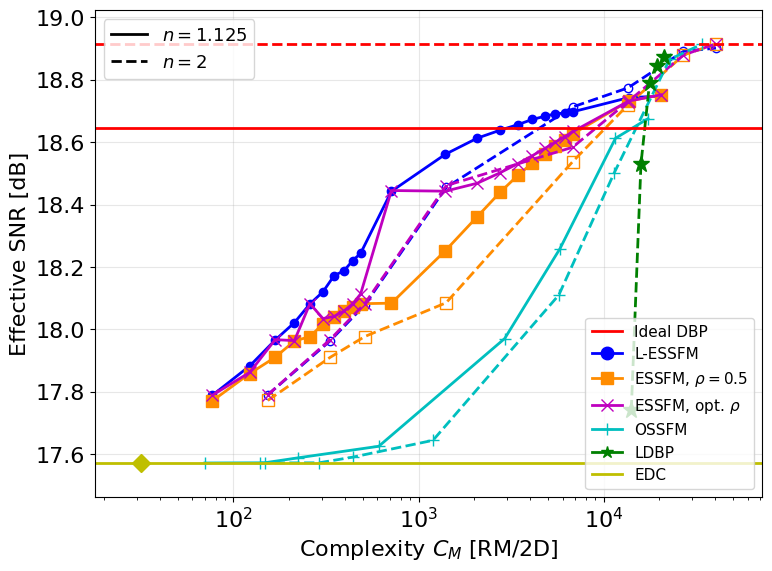

In [7]:
from result_plots import draw
draw(globals(),'complexity')
plt.show()


## 7. Same figure vs number of steps $N_s$

Identical layout, but the x-axis is the number of DBP steps $N_s$ instead of the
complexity. EDC (no DBP steps) and Ideal DBP are horizontal references. LDBP is
shown at its best point (full taps) at $N_s$ = `LDBP_NS`.

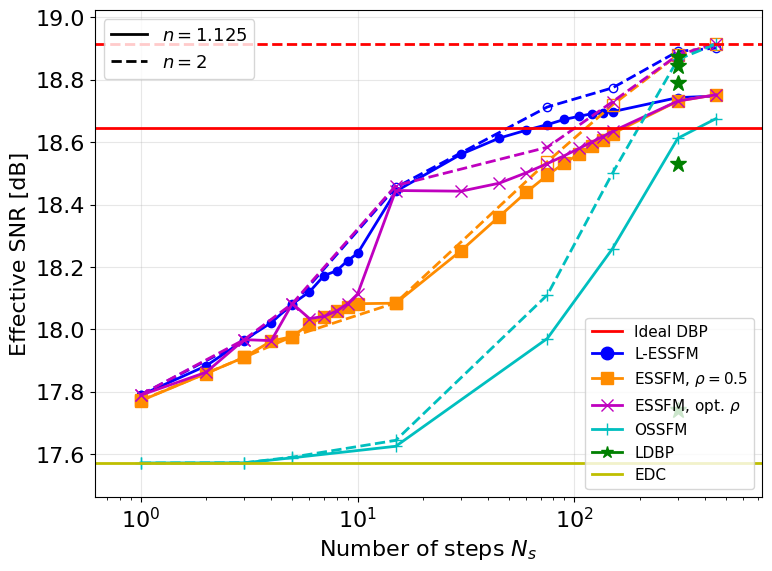

In [8]:
draw(globals(),'steps')
plt.show()
from storage import write_json, digest
summary = {name:globals()[name] for name in ('edc','ideal125','ideal2','lessfm125','lessfm2','essfm125','essfm2','essfmopt125','essfmopt2','ossfm125','ossfm2','ldbp','LDBP_TOTAL_STEPS') if name in globals()}
summary.update(scenario=SCENARIO,powers_dbm=Pgrid.tolist(),forward_manifest_sha256=digest(scenario.forward_dir/'manifest.json'),ase_mode='independent',complete=True)
summary['parameter_hashes'] = {str(p.relative_to(Path(RESDIR))):digest(p) for p in Path(RESDIR).glob('*Ns*/parameters.csv')}
write_json(Path(RESDIR)/'summary.json',summary)
